# Visualizing the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report


## Getting information about the raw dataset

label
ham     4825
spam     747
Name: count, dtype: int64
Ham/Spam Ratio: [Ham: 86.59% | Spam: 13.41%]


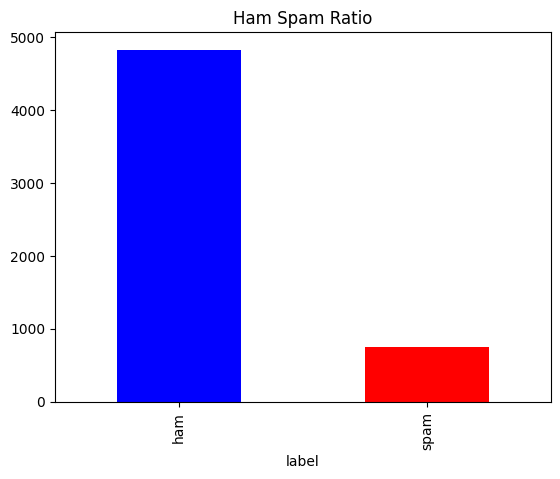

In [ ]:
df = pd.read_csv('../data/spam.csv', encoding='latin-1')
#df.head()

#removing the other columns...leaving v1 and v2 and renaming them to label and message respecively
df = df[['v1', 'v2']]
df.columns = ['label', 'message']
print(df['label'].value_counts())

ham, spam = list(df['label'].value_counts())
print(f'Ham/Spam Ratio: [Ham: {ham/(ham+spam)*100:.2f}% | Spam: {spam/(ham+spam)*100:.2f}%]')

df['label'].value_counts().plot(kind='bar', color=['blue', 'red'])
plt.title("Ham Spam Ratio")
plt.show()

## Now we do the Data Split & convert (ham => 0 and spam => 1)

In [6]:
labels = df['label'].map({'ham': 0, 'spam': 1}).values # Transform into number 0, 1
data = df['message'].values # Get a numpy ndarray

# 20% for test, %80 for train
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2)

tfidf = TfidfVectorizer(max_features=5_000) # Create a tfidf
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

## training the model

In [7]:
model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)

MultinomialNB(alpha=0.1)

# Evaluating Model & Metrics

=== Metrics ===
Accuracy: 98.92%
ROC-AUC: 0.962

=== Classification Report ===
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       981
        Spam       0.98      0.93      0.95       134

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



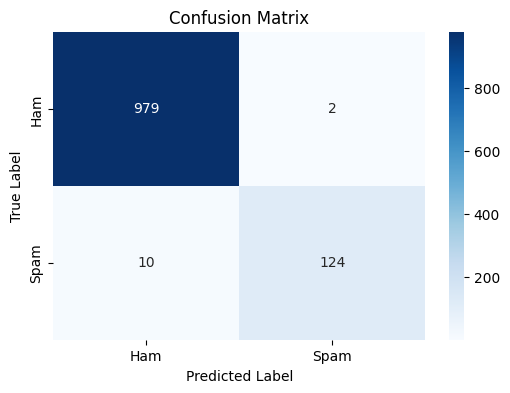

In [13]:
y_pred = model.predict(X_test)
#print(classification_report(y_test, y_pred))

# creting a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Metrics
print('=== Metrics ===')
print(f'Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%')
print(f'ROC-AUC: {roc_auc_score(y_test, y_pred):.3f}\n')

# Classification report
print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['Ham', 'Spam']))

# plotting a confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()




# Now Testing Model on Unseen Data

=== Spam Email Predictions ===
Predicted Labels: [1 1 1 1 1 0 1 1]
Spam Accuracy: 87.50%

=== Ham Email Predictions ===
Predicted Labels: [0 0 0 0 0 0 0 0]
Ham Accuracy: 100.00%

=== Classification Report ===
              precision    recall  f1-score   support

         Ham       0.89      1.00      0.94         8
        Spam       1.00      0.88      0.93         8

    accuracy                           0.94        16
   macro avg       0.94      0.94      0.94        16
weighted avg       0.94      0.94      0.94        16



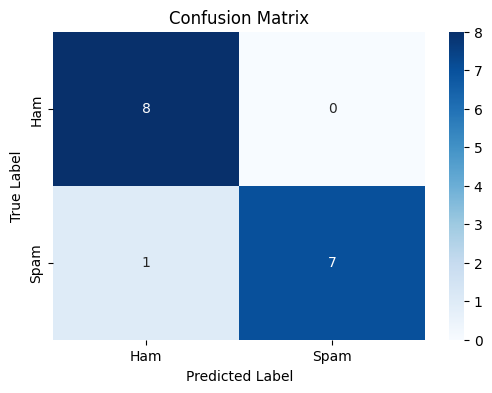

In [22]:
# Unseen test data for spam and ham emails
test_spam = [
    'Congrats! You got a free prize! Click on this link to claim the reward: http://scam.scam',
    'F1ee mone y y0u w0n $1,ooo,ooo to geL this cllck heIe: http://get_money.scam',
    'Your PayPal account has been locked! Confirm details here: http://fake-paypal-login.com',
    'Amazon Alert: Unusual activity detected. Verify now: http://amazon-security-scam.net',
    'FREE iPhone 15 Pro! Click to claim: http://freegad-offer.cc',
    'I need your help transferring $10M USD. You will be payed. Reply for details. - Dr. Abacha',
    'We have footage of you. Pay $5000 BTC or we leak it: http://blackmail-threat-web.site',
    'Inheritance notification: Congrats! You are owed $7.5 million FOR FREE. Contact: attor-scam@fake-lam.com'
]

test_ham = [
    'Hey, are we still meeting at 7pm tonight?',
    'Your doctor`s appointment is confirmed for tomorrow at 3pm.',
    'I’ll pick up groceries on the way home. Need anything?',
    'The project deadline has been extended to Friday.',
    'Thanks for the notes from yesterday’s meeting!',
    'Can you send me the recipe for that pasta dish?',
    'Mom called and said she’ll visit next weekend.',
    'The team lunch is at the new Italian place downtown.'
]

# transforming emails using TF-IDF vectorizers
spam_emails = tfidf.transform(test_spam)
ham_emails = tfidf.transform(test_ham)

# making predictions
spam_pred = model.predict(spam_emails)
ham_pred = model.predict(ham_emails)

# define true labels
spam_true = np.ones(len(test_spam), dtype=int)
ham_true = np.zeros(len(test_ham), dtype=int)

#calculate accuracies
spam_accuracy = np.mean(spam_pred == spam_true) * 100
ham_accuracy = np.mean(ham_pred == ham_true) * 100

# display predictions and accuracy
print('=== Spam Email Predictions ===')
print(f'Predicted Labels: {spam_pred}')
print(f'Spam Accuracy: {spam_accuracy:.2f}%\n')

print('=== Ham Email Predictions ===')
print(f'Predicted Labels: {ham_pred}')
print(f'Ham Accuracy: {ham_accuracy:.2f}%\n')



# combined result of overall metrics

y_true = np.concatenate([spam_true, ham_true])
y_pred = np.concatenate([spam_pred, ham_pred])

print('=== Classification Report ===')
print(classification_report(y_true, y_pred, target_names=['Ham', 'Spam']))


# Create a confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()
